# Quickstart: regression

Fit a DJINN regressor on the California housing data, check how well it does,
then save it, load it and keep training.

In [1]:
import os
import shutil

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

from djinn import DJINN_Regressor, load

## Data

The full dataset has about 20,000 rows and 8 features. The target is the
median house value of a block group in units of $100,000. A random 3,000 rows
are enough here and keep the notebook quick.

In [2]:
X, y = fetch_california_housing(return_X_y=True)
rng = np.random.default_rng(0)
idx = rng.choice(len(y), 3000, replace=False)
X_train, X_test, y_train, y_test = train_test_split(
    X[idx], y[idx], test_size=0.2, random_state=0
)
X_train.shape, X_test.shape

((2400, 8), (600, 8))

## Choosing a learning rate

If `learning_rate` is left as `None`, `fit()` searches for a learning rate,
number of epochs and batch size before it trains. The search can also be run on
its own with `get_hyperparameters()`, and the results passed to the
constructor. That's worth doing when you'll fit the same data more than once,
since the search takes longer than the training itself.

In [3]:
%%time
search = DJINN_Regressor(n_trees=1, max_tree_depth=6, random_state=0)
hyper = search.get_hyperparameters(X_train, y_train, seed=0)
hyper

CPU times: user 11min 39s, sys: 57.4 s, total: 12min 36s
Wall time: 1min 3s


{'batch_size': 120,
 'learning_rate': 0.0054612805388816795,
 'learn_rate': 0.0054612805388816795,
 'epochs': 210,
 'ntrees': 1}

## Fit

`n_trees` is the number of trees in the random forest, and so the number of
networks in the ensemble. `max_tree_depth` limits how deep each tree grows,
and the network built from a tree has `max_tree_depth - 1` hidden layers.

In [4]:
%%time
model = DJINN_Regressor(
    n_trees=3,
    max_tree_depth=6,
    learning_rate=hyper["learning_rate"],
    epochs=hyper["epochs"],
    batch_size=hyper["batch_size"],
    random_state=0,
)
model.fit(X_train, y_train)

CPU times: user 3min 9s, sys: 15.5 s, total: 3min 24s
Wall time: 17.1 s


DJINN_Regressor(batch_size=120, epochs=210, learning_rate=0.0054612805388816795,
                max_tree_depth=6, n_trees=3, random_state=0)

## Predict

`predict()` runs each network once with dropout off and averages them.
`score()` returns R², like any scikit-learn regressor.

In [5]:
y_pred = model.predict(X_test)
print(f"R2 on the test set: {model.score(X_test, y_test):.3f}")

R2 on the test set: 0.671


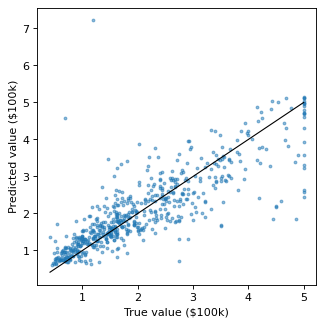

In [6]:
fig, ax = plt.subplots(figsize=(4.5, 4.5), dpi=80)
ax.scatter(y_test, y_pred, s=6, alpha=0.5)
lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, color="k", lw=1)
ax.set_xlabel("True value ($100k)")
ax.set_ylabel("Predicted value ($100k)")
plt.show()

Each network trains on 90% of the training data. The other 10% is held back,
and the loss on it is recorded every epoch. Both curves are kept in
`nninfo_`, in units of the scaled targets.

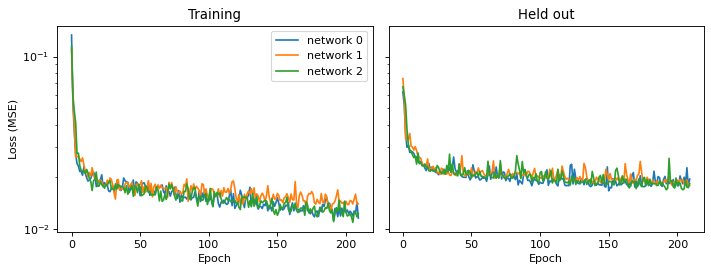

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5), dpi=80, sharey=True)
for ax, key, title in zip(axs, ["train_cost", "valid_cost"], ["Training", "Held out"]):
    for i, cost in enumerate(model.nninfo_[key]):
        ax.plot(cost, label=f"network {i}")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_yscale("log")
axs[0].set_ylabel("Loss (MSE)")
axs[0].legend()
fig.tight_layout()
plt.show()

## Save, load and keep training

`save()` writes one checkpoint per network to a folder, plus a `.json` file
with the settings and scalers. `load()` returns a model that's ready to
predict, and `continue_training()` picks up where training stopped.

In [8]:
model.save("quickstart_model", overwrite=True)

reloaded = load("quickstart_model")
np.allclose(reloaded.predict(X_test), y_pred)

True

In [9]:
reloaded.continue_training(
    X_train,
    y_train,
    training_epochs=100,
    learning_rate=hyper["learning_rate"],
    batch_size=hyper["batch_size"],
    seed=0,
)
print(f"R2 after 100 more epochs: {reloaded.score(X_test, y_test):.3f}")

R2 after 100 more epochs: 0.718


Clean up the saved files.

In [10]:
shutil.rmtree("quickstart_model")
os.remove("quickstart_model.json")